<a href="https://colab.research.google.com/github/ryanglenc/MAT_442/blob/main/Mat_422_HW_3_7.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# MAT 422 - Homework 9: Section 3.7
### Artificial Neural Networks

This notebook builds a neural network from scratch in NumPy, covering the mathematical formulation, activation functions, cost functions, backpropagation, and the full backpropagation training algorithm.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_moons
np.set_printoptions(precision=4, suppress=True)
rng = np.random.default_rng(42)

## 3.7.1 Mathematical Formulation

A feedforward neural network is a composition of simple layers. Layer ℓ takes the previous layer's output a^(ℓ−1) and computes

z^(ℓ) = W^(ℓ) a^(ℓ−1) + b^(ℓ),   a^(ℓ) = σ(z^(ℓ))

where W^(ℓ) is a weight matrix, b^(ℓ) is a bias vector, and σ is an **activation function** applied entry by entry. The input is a^(0) = x, and the network's output is a^(L). If layer ℓ has n_ℓ neurons, then W^(ℓ) has shape n_ℓ × n_(ℓ−1).

So the network is a function f(x; W, b) = σ(W^(L) σ( ... σ(W^(1) x + b^(1)) ...) + b^(L)), and "learning" means choosing the parameters W, b so that f fits the data.

We build a small 2 → 3 → 1 network (2 inputs, 3 hidden neurons, 1 output), compute its output for one input, and check that the matrix formula agrees with computing each neuron one at a time.

In [2]:
def sigmoid(z):
    return 1.0 / (1.0 + np.exp(-z))

# Network: 2 inputs -> 3 hidden neurons -> 1 output
W1 = rng.normal(size=(3, 2)); b1 = rng.normal(size=(3, 1))
W2 = rng.normal(size=(1, 3)); b2 = rng.normal(size=(1, 1))
x = np.array([[0.5], [-1.0]])

print("Shapes: W1", W1.shape, " b1", b1.shape, " W2", W2.shape, " b2", b2.shape)
print("Number of parameters:", W1.size + b1.size + W2.size + b2.size)

# Forward pass in matrix form
z1 = W1 @ x + b1
a1 = sigmoid(z1)
z2 = W2 @ a1 + b2
a2 = sigmoid(z2)
print("\nHidden layer output a1:", a1.ravel())
print("Network output a2:     ", a2.ravel())

# Check: compute each hidden neuron separately from the definition
manual = []
for j in range(3):
    s = sum(W1[j, k] * x[k, 0] for k in range(2)) + b1[j, 0]
    manual.append(1 / (1 + np.exp(-s)))
print("\nNeuron-by-neuron matches matrix form:", np.allclose(manual, a1.ravel()))

# The same formulas process many inputs at once if each column is one example
X_batch = rng.normal(size=(2, 5))
out_batch = sigmoid(W2 @ sigmoid(W1 @ X_batch + b1) + b2)
print("Output for a batch of 5 inputs has shape", out_batch.shape)

Shapes: W1 (3, 2)  b1 (3, 1)  W2 (1, 3)  b2 (1, 1)
Number of parameters: 13

Hidden layer output a1: [0.7892 0.2929 0.5769]
Network output a2:      [0.5247]

Neuron-by-neuron matches matrix form: True
Output for a batch of 5 inputs has shape (1, 5)


## 3.7.2 Activation Functions

The activation σ must be **nonlinear**. If it were linear, stacking layers would add nothing: W2(W1 x + b1) + b2 = (W2 W1)x + (W2 b1 + b2) is just one linear map. We verify this below.

Common choices and their derivatives (needed for backpropagation):

| Name | σ(z) | σ'(z) |
|---|---|---|
| Sigmoid | 1 / (1 + e^(−z)) | σ(z)(1 − σ(z)) |
| tanh | tanh(z) | 1 − tanh²(z) |
| ReLU | max(0, z) | 1 if z > 0, else 0 |
| Leaky ReLU | z if z > 0, else 0.01z | 1 if z > 0, else 0.01 |

The sigmoid's derivative is never larger than 0.25. Backpropagation multiplies one derivative per layer, so in deep sigmoid networks the gradient can shrink toward zero (the **vanishing gradient** problem). This is one reason ReLU is popular.

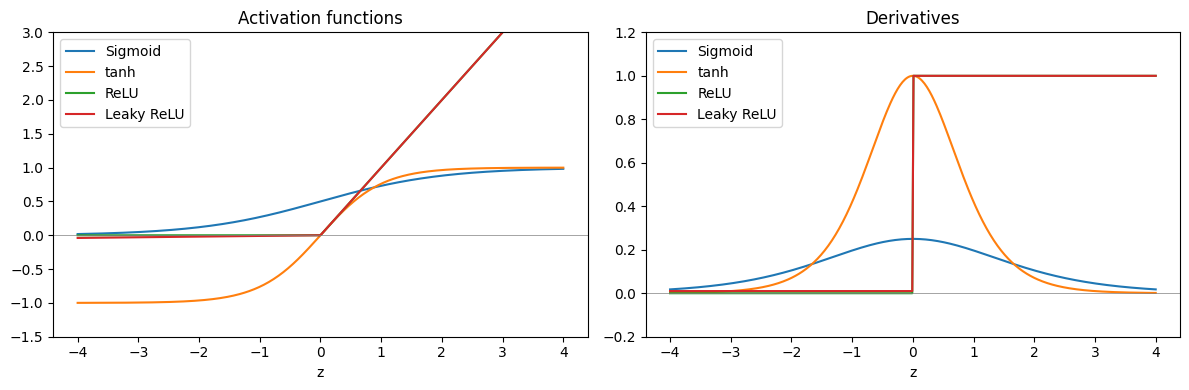

Derivative formula matches finite differences:
  Sigmoid     True
  tanh        True
  ReLU        True
  Leaky ReLU  True


In [3]:
activations = {
    'Sigmoid':    (sigmoid,                                lambda z: sigmoid(z) * (1 - sigmoid(z))),
    'tanh':       (np.tanh,                                lambda z: 1 - np.tanh(z) ** 2),
    'ReLU':       (lambda z: np.maximum(0, z),             lambda z: (z > 0).astype(float)),
    'Leaky ReLU': (lambda z: np.where(z > 0, z, 0.01 * z), lambda z: np.where(z > 0, 1.0, 0.01)),
}

z = np.linspace(-4, 4, 400)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for name, (f, df) in activations.items():
    axes[0].plot(z, f(z), label=name)
    axes[1].plot(z, df(z), label=name)
axes[0].set_title('Activation functions'); axes[0].set_ylim(-1.5, 3); axes[0].legend()
axes[1].set_title('Derivatives'); axes[1].set_ylim(-0.2, 1.2); axes[1].legend()
for ax in axes:
    ax.set_xlabel('z'); ax.axhline(0, color='gray', linewidth=0.5)
plt.tight_layout()
plt.show()

# Check each derivative formula against a central finite difference
test_points = np.array([-2, -1, -0.5, 0.5, 1, 2.0])   # avoid z = 0, where ReLU is not differentiable
h = 1e-6
print("Derivative formula matches finite differences:")
for name, (f, df) in activations.items():
    numeric = (f(test_points + h) - f(test_points - h)) / (2 * h)
    print(f"  {name:11s}", np.allclose(numeric, df(test_points), atol=1e-6))

In [4]:
# 1) Two linear layers collapse into one linear layer
A1 = rng.normal(size=(4, 2)); B1 = rng.normal(size=(4, 1))
A2 = rng.normal(size=(1, 4)); B2 = rng.normal(size=(1, 1))
X = rng.normal(size=(2, 5))

two_layers = A2 @ (A1 @ X + B1) + B2
one_layer = (A2 @ A1) @ X + (A2 @ B1 + B2)
print("Two linear layers equal ONE linear layer:", np.allclose(two_layers, one_layer))

# 2) Vanishing gradients: the largest possible sigmoid derivative is 0.25
max_deriv = np.max(activations['Sigmoid'][1](z))
print(f"\nMaximum of the sigmoid derivative: {max_deriv:.4f}")
for depth in (2, 5, 10):
    print(f"  Best-case gradient factor through {depth:2d} sigmoid layers: {max_deriv ** depth:.2e}")

Two linear layers equal ONE linear layer: True

Maximum of the sigmoid derivative: 0.2500
  Best-case gradient factor through  2 sigmoid layers: 6.25e-02
  Best-case gradient factor through  5 sigmoid layers: 9.76e-04
  Best-case gradient factor through 10 sigmoid layers: 9.53e-07


## 3.7.3 Cost Function

To train the network we need a number that measures how wrong its predictions are. For m training examples (xᵢ, yᵢ) with network outputs aᵢ, two standard costs are:

**Mean squared error (MSE):**  C = (1/2m) Σᵢ ‖aᵢ − yᵢ‖²

**Binary cross-entropy** (for 0/1 labels, with a sigmoid output):  C = −(1/m) Σᵢ [ yᵢ log aᵢ + (1 − yᵢ) log(1 − aᵢ) ]

Training means minimizing C over the parameters W, b. Cross-entropy is the negative log-likelihood from Section 3.4, so a sigmoid output with cross-entropy is exactly logistic regression on top of learned features.

The choice of cost affects the gradient. With a sigmoid output, the gradient of the cost with respect to the output pre-activation z is:
- MSE: (a − y) · σ'(z) = (a − y) · a(1 − a), which **becomes tiny when the neuron saturates** (a near 0 or 1), even if it is badly wrong.
- Cross-entropy: simply a − y, with the σ' factor canceling.

We compare the two costs and verify the cross-entropy simplification numerically.

Network output: [0.5247]   label: [1.]
MSE cost:           0.112940864228976
Cross-entropy cost: 0.6448717462739012


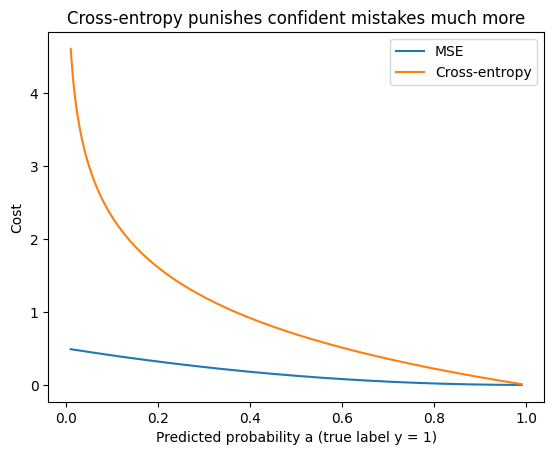


Finite-difference dC/dz = -0.425557,  sigmoid(z) - y = -0.425557


In [5]:
def mse_cost(a, y):
    return 0.5 * np.mean(np.sum((a - y) ** 2, axis=0))

def bce_cost(a, y):
    a = np.clip(a, 1e-12, 1 - 1e-12)
    return -np.mean(y * np.log(a) + (1 - y) * np.log(1 - a))

# Cost of the network from 3.7.1 on a single example with label y = 1
y_true = np.array([[1.0]])
print("Network output:", a2.ravel(), "  label:", y_true.ravel())
print("MSE cost:          ", mse_cost(a2, y_true))
print("Cross-entropy cost:", bce_cost(a2, y_true))

# Compare the penalty when the true label is 1 and the prediction a varies
a_vals = np.linspace(0.01, 0.99, 200)
plt.plot(a_vals, 0.5 * (a_vals - 1) ** 2, label='MSE')
plt.plot(a_vals, -np.log(a_vals), label='Cross-entropy')
plt.xlabel('Predicted probability a (true label y = 1)')
plt.ylabel('Cost')
plt.title('Cross-entropy punishes confident mistakes much more')
plt.legend()
plt.show()

# Verify: d(cross-entropy)/dz = sigmoid(z) - y  for a sigmoid output
z0, y0, eps = 0.3, 1.0, 1e-6
ce_of_z = lambda zv: -(y0 * np.log(sigmoid(zv)) + (1 - y0) * np.log(1 - sigmoid(zv)))
numeric = (ce_of_z(z0 + eps) - ce_of_z(z0 - eps)) / (2 * eps)
print(f"\nFinite-difference dC/dz = {numeric:.6f},  sigmoid(z) - y = {sigmoid(z0) - y0:.6f}")

## 3.7.4 Backpropagation

Gradient descent needs ∇C, the derivative of the cost with respect to every weight and bias. **Backpropagation** computes all of them efficiently using the chain rule, working backward from the output.

Define the **error signal** of layer ℓ as δ^(ℓ) = ∂C/∂z^(ℓ). For a single example, with ⊙ meaning entrywise multiplication, the chain rule gives:

1. **Output layer:**  δ^(L) = (a^(L) − y) ⊙ σ'(z^(L))   (for the MSE cost)
2. **Hidden layers (going backward):**  δ^(ℓ) = ( (W^(ℓ+1))ᵀ δ^(ℓ+1) ) ⊙ σ'(z^(ℓ))
3. **Gradients:**  ∂C/∂W^(ℓ) = δ^(ℓ) (a^(ℓ−1))ᵀ,   ∂C/∂b^(ℓ) = δ^(ℓ)

Step 2 is the key: the error at layer ℓ is the error at layer ℓ+1 sent back through the transposed weights, then scaled by the local slope of the activation. Reusing δ^(ℓ+1) is what makes backpropagation cheap.

We apply these formulas to our 2 → 3 → 1 network and check every gradient against a slow but trustworthy **numerical gradient** (central finite differences). Agreement is the standard way to test a backpropagation implementation.

In [6]:
def forward(W1, b1, W2, b2, x):
    z1 = W1 @ x + b1;  a1 = sigmoid(z1)
    z2 = W2 @ a1 + b2; a2 = sigmoid(z2)
    return z1, a1, z2, a2

def cost(params):
    return 0.5 * np.sum((forward(*params, x)[3] - y_true) ** 2)

# Forward pass (keeping the intermediate values)
z1, a1, z2, a2 = forward(W1, b1, W2, b2, x)

# Backward pass using the formulas above
delta2 = (a2 - y_true) * a2 * (1 - a2)            # output layer error signal
dW2 = delta2 @ a1.T
db2 = delta2

delta1 = (W2.T @ delta2) * a1 * (1 - a1)          # error sent back to the hidden layer
dW1 = delta1 @ x.T
db1 = delta1

params = [W1, b1, W2, b2]
backprop_grads = [dW1, db1, dW2, db2]
names = ['W1', 'b1', 'W2', 'b2']

# Numerical gradient: perturb each parameter entry up and down
eps = 1e-6
print("Backpropagation vs numerical gradient (max absolute difference):")
for name, p, g in zip(names, params, backprop_grads):
    numeric = np.zeros_like(p)
    for idx in np.ndindex(*p.shape):
        old = p[idx]
        p[idx] = old + eps; c_plus = cost(params)
        p[idx] = old - eps; c_minus = cost(params)
        p[idx] = old
        numeric[idx] = (c_plus - c_minus) / (2 * eps)
    print(f"  {name}: {np.max(np.abs(numeric - g)):.2e}")

print("\ndW1 from backprop:\n", dW1)

Backpropagation vs numerical gradient (max absolute difference):
  W1: 3.90e-11
  b1: 2.32e-11
  W2: 2.07e-11
  b2: 1.61e-12

dW1 from backprop:
 [[ 0.0084 -0.0168]
 [-0.0108  0.0216]
 [-0.0113  0.0225]]


## 3.7.5 The Backpropagation Algorithm

Now we put everything together into the full training algorithm for a network with any number of layers. Each iteration (epoch) does:

1. **Forward pass:** compute and store z^(ℓ), a^(ℓ) for every layer.
2. **Compute the cost** C.
3. **Backward pass:** compute δ^(L), then δ^(ℓ) for ℓ = L−1, ..., 1, and the gradients ∂C/∂W^(ℓ), ∂C/∂b^(ℓ).
4. **Gradient descent update:**  W^(ℓ) ← W^(ℓ) − α ∂C/∂W^(ℓ),  b^(ℓ) ← b^(ℓ) − α ∂C/∂b^(ℓ).

Here the gradients are averaged over all m training examples (each column of X is one example). The class below supports both costs from 3.7.3: for cross-entropy the output δ is simply a − y.

In [7]:
class NeuralNet:
    def __init__(self, sizes, loss='ce', seed=0):
        """sizes = [n_inputs, n_hidden1, ..., n_outputs]; loss is 'mse' or 'ce'."""
        r = np.random.default_rng(seed)
        self.loss = loss
        self.W = [r.normal(size=(sizes[i + 1], sizes[i])) * np.sqrt(1 / sizes[i])
                  for i in range(len(sizes) - 1)]
        self.b = [np.zeros((sizes[i + 1], 1)) for i in range(len(sizes) - 1)]

    def forward(self, X):
        """Returns the list of activations [a0 = X, a1, ..., aL]."""
        A = [X]
        for W, b in zip(self.W, self.b):
            A.append(sigmoid(W @ A[-1] + b))
        return A

    def cost(self, X, Y):
        out = self.forward(X)[-1]
        m = X.shape[1]
        if self.loss == 'mse':
            return 0.5 * np.sum((out - Y) ** 2) / m
        out = np.clip(out, 1e-12, 1 - 1e-12)
        return -np.sum(Y * np.log(out) + (1 - Y) * np.log(1 - out)) / m

    def backward(self, X, Y):
        """Backpropagation: returns the gradients dW, db for every layer."""
        m = X.shape[1]
        A = self.forward(X)
        L = len(self.W)
        dW, db = [None] * L, [None] * L

        # Output layer error signal
        if self.loss == 'ce':
            delta = A[-1] - Y
        else:
            delta = (A[-1] - Y) * A[-1] * (1 - A[-1])

        # Walk backward through the layers
        for l in reversed(range(L)):
            dW[l] = delta @ A[l].T / m
            db[l] = delta.sum(axis=1, keepdims=True) / m
            if l > 0:
                delta = (self.W[l].T @ delta) * A[l] * (1 - A[l])
        return dW, db

    def train(self, X, Y, lr, epochs):
        history = []
        for _ in range(epochs):
            dW, db = self.backward(X, Y)
            for l in range(len(self.W)):
                self.W[l] -= lr * dW[l]
                self.b[l] -= lr * db[l]
            history.append(self.cost(X, Y))
        return np.array(history)

    def predict(self, X):
        return (self.forward(X)[-1] > 0.5).astype(int)

In [8]:
# Verify the general implementation against numerical gradients, for both costs
Xg = rng.normal(size=(2, 6))
Yg = (rng.random((1, 6)) > 0.5).astype(float)

for loss in ['mse', 'ce']:
    net = NeuralNet([2, 3, 1], loss=loss, seed=1)
    dW, db = net.backward(Xg, Yg)
    worst = 0
    for P, G in [(net.W, dW), (net.b, db)]:
        for l in range(len(P)):
            for idx in np.ndindex(*P[l].shape):
                old = P[l][idx]
                P[l][idx] = old + 1e-6; c_plus = net.cost(Xg, Yg)
                P[l][idx] = old - 1e-6; c_minus = net.cost(Xg, Yg)
                P[l][idx] = old
                worst = max(worst, abs((c_plus - c_minus) / 2e-6 - G[l][idx]))
    print(f"loss = {loss:3s}: max gradient error = {worst:.2e}")

loss = mse: max gradient error = 1.49e-11
loss = ce : max gradient error = 1.02e-10


Cost before training: 0.7483176725388063
Cost after training:  0.000690467458583838

Inputs (columns):
 [[0. 0. 1. 1.]
 [0. 1. 0. 1.]]
Predicted probabilities: [0.0009 0.999  0.9997 0.0006]
Predicted classes:       [0 1 1 0]
True labels:             [0 1 1 0]


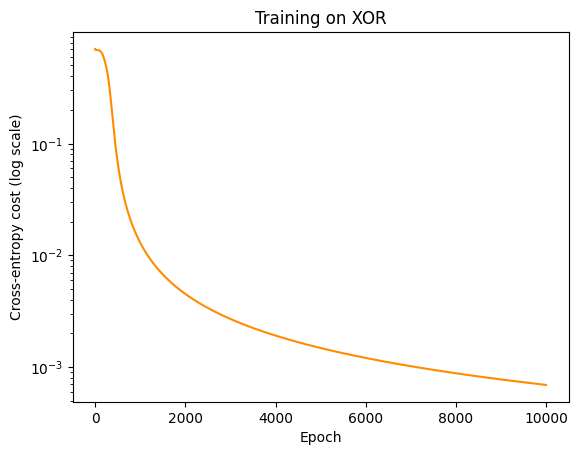

In [9]:
# XOR: the classic problem that no single linear classifier can solve
X_xor = np.array([[0, 0, 1, 1],
                  [0, 1, 0, 1]], dtype=float)
Y_xor = np.array([[0, 1, 1, 0]], dtype=float)

net_xor = NeuralNet([2, 4, 1], loss='ce', seed=0)
print("Cost before training:", net_xor.cost(X_xor, Y_xor))

history = net_xor.train(X_xor, Y_xor, lr=1.0, epochs=10000)

print("Cost after training: ", history[-1])
print("\nInputs (columns):\n", X_xor)
print("Predicted probabilities:", net_xor.forward(X_xor)[-1].ravel())
print("Predicted classes:      ", net_xor.predict(X_xor).ravel())
print("True labels:            ", Y_xor.ravel().astype(int))

plt.semilogy(history, color='darkorange')
plt.xlabel('Epoch'); plt.ylabel('Cross-entropy cost (log scale)')
plt.title('Training on XOR')
plt.show()

XOR has labels 1 when exactly one input is 1. The points (0,0) and (1,1) have label 0, and (0,1) and (1,0) have label 1, so no straight line separates the classes. The hidden layer transforms the inputs into new features in which the classes *can* be separated by a line, which is what the output neuron then does.

Neural network accuracy:         0.983
Logistic regression accuracy:    0.847


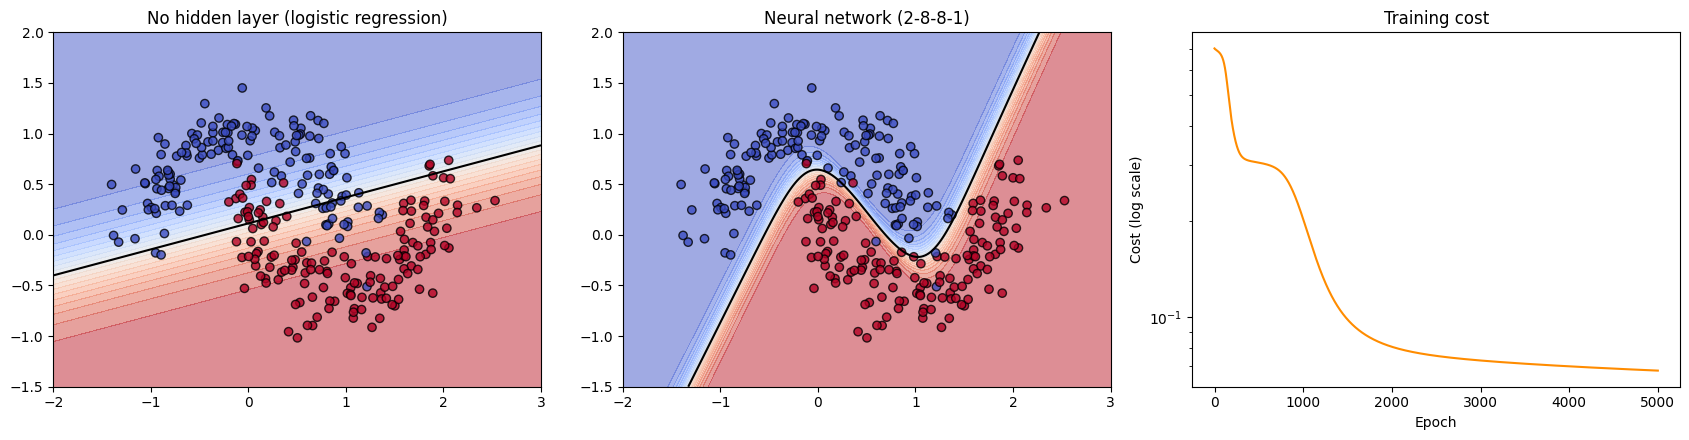

In [10]:
X_m, y_m = make_moons(n_samples=300, noise=0.2, random_state=0)
Xm, Ym = X_m.T, y_m.reshape(1, -1).astype(float)    # columns = examples

# Network with two hidden layers of 8 neurons
net = NeuralNet([2, 8, 8, 1], loss='ce', seed=0)
hist = net.train(Xm, Ym, lr=0.5, epochs=5000)

# Baseline: no hidden layer at all (this is just logistic regression)
logreg = NeuralNet([2, 1], loss='ce', seed=0)
logreg.train(Xm, Ym, lr=0.5, epochs=5000)

print(f"Neural network accuracy:         {np.mean(net.predict(Xm) == Ym):.3f}")
print(f"Logistic regression accuracy:    {np.mean(logreg.predict(Xm) == Ym):.3f}")

# Plot the decision regions
xx, yy = np.meshgrid(np.linspace(-2, 3, 300), np.linspace(-1.5, 2, 300))
grid = np.vstack((xx.ravel(), yy.ravel()))

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
for ax, model, title in [(axes[0], logreg, 'No hidden layer (logistic regression)'),
                         (axes[1], net, 'Neural network (2-8-8-1)')]:
    Z = model.forward(grid)[-1].reshape(xx.shape)
    ax.contourf(xx, yy, Z, levels=20, cmap='coolwarm', alpha=0.5)
    ax.contour(xx, yy, Z, levels=[0.5], colors='k')
    ax.scatter(X_m[:, 0], X_m[:, 1], c=y_m, cmap='coolwarm', edgecolor='k', alpha=0.8)
    ax.set_title(title)
axes[2].semilogy(hist, color='darkorange')
axes[2].set_xlabel('Epoch'); axes[2].set_ylabel('Cost (log scale)'); axes[2].set_title('Training cost')
plt.tight_layout()
plt.show()

## Summary

- **3.7.1 Formulation:** A network is a composition of layers z = Wa + b, a = σ(z). Built a 2-3-1 network, computed a forward pass, and checked the matrix form against neuron-by-neuron computation.
- **3.7.2 Activation functions:** Plotted sigmoid, tanh, ReLU, and leaky ReLU with their derivatives (verified numerically), showed that without a nonlinearity stacked layers collapse into a single linear map, and showed how sigmoid derivatives cause vanishing gradients.
- **3.7.3 Cost function:** Compared MSE and cross-entropy, and verified that for a sigmoid output the cross-entropy gradient simplifies to a − y.
- **3.7.4 Backpropagation:** Derived the error-signal recursion from the chain rule and verified all gradients of a small network against numerical gradients.
- **3.7.5 Backpropagation algorithm:** Implemented a general multi-layer network with forward pass, backward pass, and gradient-descent updates, verified its gradients for both costs, and trained it on XOR and on the two-moons dataset, where it outperforms a model with no hidden layer.